# Tune SEI densities (rho_EC, rho_VC)

**Context**: This notebook sweeps the SEI **densities** (`rho_EC` and `rho_VC`)
while holding the SEI **diffusivities** (`D_LEDC` and `D_LVDC`) fixed at their
previously-tuned values.  This corresponds to the "Set densities" stage of the
SEI parameter tuning workflow.

This is a copy of just the **densities** portion of
`2026_02_25_ec_tuning.ipynb`, extracted into its own notebook so it can be
re-run independently of the diffusivity and conductivity tuning steps.

Pipeline:

1. Load experimental data (`expt1`–`expt4`) and interpolate currents.
2. Smooth the early-time kink artefact in the experimental expansion curves.
3. Sweep `rho_EC` × `rho_VC` over a 35×36 grid using fixed
   `D_LEDC = D_LVDC = 4.44e-20` / `1.3e-17` (m^2/s) tuned values.
4. Pickle the resulting RMSE / capacity / resistance matrices.
5. Plot voltage and expansion RMSE heatmaps using `simutils.plot_heatmaps_rho`.

Andrew Weng

In [2]:
import os, sys

if os.path.basename(os.getcwd()) in ('notebooks', 'notebooks_2026'):
    os.chdir('../')
    sys.path.insert(0, 'src/')

from src import cellsim as cellsim

from scipy.interpolate import interp1d

import pickle
import numpy as np
from matplotlib import pyplot as plt
from src import plotter as plotter
from src import ioutils as ioutils
from src import simutils as simutils

%load_ext autoreload
%matplotlib inline

plotter.initialize(plt)

# Load the experimental data

In [2]:
# Load the experimental data
expt1, _ = ioutils.fetch_experimental_data(152064, 600)
expt2, _ = ioutils.fetch_experimental_data(152074, 600)
expt3, _ = ioutils.fetch_experimental_data(152071, 600)
expt4, _ = ioutils.fetch_experimental_data(152098, 600)


dt_data_interp = 5.0
t_interp1, i_interp1 = simutils.interpolate_raw_data(expt1['arbin_time'], expt1['arbin_current'], dt_data_interp)
t_interp2, i_interp2 = simutils.interpolate_raw_data(expt2['arbin_time'], expt2['arbin_current'], dt_data_interp)
t_interp3, i_interp3 = simutils.interpolate_raw_data(expt3['arbin_time'], expt3['arbin_current'], dt_data_interp)
t_interp4, i_interp4 = simutils.interpolate_raw_data(expt4['arbin_time'], expt4['arbin_current'], dt_data_interp)

In [3]:
# Smooth the early-time kink artefact in expansion data
# Format: (expt, label, t_start, t_end)
kink_regions = [
    (expt1, 'Base 1', 0.5, 0.75),
    (expt2, 'Base 2', 0.5, 0.85),
    (expt3, 'Fast', 0.5, 0.6),
    (expt4, 'Fast+', 0.5, 0.55),
]

smoothed_strains = {}
for expt, label, t_start, t_end in kink_regions:
    daq_time = np.array(expt['daq_time'])
    daq_strain = np.array(expt['daq_strain'])
    daq_time_hours = (daq_time - daq_time[0]) / 3600.0
    strain_smoothed = ioutils.smooth_kink_region(daq_time_hours, daq_strain, t_start, t_end)
    smoothed_strains[label] = {
        'time_hours': daq_time_hours,
        'original': daq_strain,
        'smoothed': strain_smoothed,
        't_start': t_start,
        't_end': t_end,
    }

expt1['daq_strain_smoothed'] = smoothed_strains['Base 1']['smoothed']
expt2['daq_strain_smoothed'] = smoothed_strains['Base 2']['smoothed']
expt3['daq_strain_smoothed'] = smoothed_strains['Fast']['smoothed']
expt4['daq_strain_smoothed'] = smoothed_strains['Fast+']['smoothed']

# Set densities

In [4]:
# Tuning based on voltage
d_ec_opt1 = 6.66e-20
d_ec_opt2 = 6.66e-20
d_ec_opt3 = 6.66e-20
d_vc_opt1 = 1.22e-18
d_vc_opt2 = 1.22e-18
d_vc_opt3 = 1.22e-18

nn = 35

rho_ec_vec = np.linspace(0.5, 4, nn)
rho_vc_vec = np.linspace(0.5, 4, nn+1)

shape = (len(rho_ec_vec), len(rho_vc_vec))
_mat_names = [
    'rmse1_e_mat', 'rmse1_v_mat', 'rmse2_e_mat', 'rmse2_v_mat', 'rmse3_e_mat', 'rmse3_v_mat',
    'qsei1_mat', 'qsei2_mat', 'qsei3_mat', 'qsei1_vc_mat', 'qsei2_vc_mat', 'qsei3_vc_mat',
    'expan1_mat', 'expan2_mat', 'expan3_mat',
    'resistance1_mat', 'resistance2_mat', 'resistance3_mat',
]
for _name in _mat_names:
    globals()[_name] = np.zeros(shape)

count = 1

for i, rho_ec in enumerate(rho_ec_vec):
    for j, rho_vc in enumerate(rho_vc_vec):

        print(f'Running rho_EC = {rho_ec:.2e} | rho_VC = {rho_vc:.2e} ({count} of {nn*(nn+1)})')
        count += 1

        try:
            df_sim1 = simutils.run_sim('base', d_ec_opt1, d_vc_opt1, rho_ec=rho_ec, rho_vc=rho_vc, dt=1, include_flag=3)
            df_sim2 = simutils.run_sim('fast', d_ec_opt2, d_vc_opt2, rho_ec=rho_ec, rho_vc=rho_vc, dt=1, include_flag=3)
            df_sim3 = simutils.run_sim('fast+', d_ec_opt3, d_vc_opt3, rho_ec=rho_ec, rho_vc=rho_vc, dt=1, include_flag=3)
        except:
            print('ERROR')
            continue

        # Extract the qsei values:
        qsei1_mat[i, j] = df_sim1['q_sei'].iloc[-1]
        qsei2_mat[i, j] = df_sim2['q_sei'].iloc[-1]
        qsei3_mat[i, j] = df_sim3['q_sei'].iloc[-1]

        qsei1_vc_mat[i, j] = df_sim1['q_sei2'].iloc[-1]
        qsei2_vc_mat[i, j] = df_sim2['q_sei2'].iloc[-1]
        qsei3_vc_mat[i, j] = df_sim3['q_sei2'].iloc[-1]

        # Extract the expansion values:
        expan1_mat[i, j] = df_sim1['expansion'].iloc[-1]
        expan2_mat[i, j] = df_sim2['expansion'].iloc[-1]
        expan3_mat[i, j] = df_sim3['expansion'].iloc[-1]

        # Extract the resistance values:
        resistance1_mat[i, j] = df_sim1['R_sei'].iloc[-1]
        resistance2_mat[i, j] = df_sim2['R_sei'].iloc[-1]
        resistance3_mat[i, j] = df_sim3['R_sei'].iloc[-1]

        # Beware of experimental vs model data indexing!
        rmse1_v, _, _ = simutils.calculate_rmse(expt1['arbin_time'], expt1['arbin_voltage'], df_sim1['t'], df_sim1['vt'], y_range=(3.2, 4.2), ignore_time_range=(0,30*60))
        rmse1_e, _, _ = simutils.calculate_rmse(expt1['daq_time'],   expt1['daq_strain'], df_sim1['t'], df_sim1['expansion']*1e6, ignore_time_range=(0,30*60))
        rmse2_v, _, _ = simutils.calculate_rmse(expt3['arbin_time'], expt3['arbin_voltage'], df_sim2['t'], df_sim2['vt'], y_range=(3.2, 4.2), ignore_time_range=(0,30*60))
        rmse2_e, _, _ = simutils.calculate_rmse(expt3['daq_time'],   expt3['daq_strain'], df_sim2['t'], df_sim2['expansion']*1e6, ignore_time_range=(0,30*60))
        rmse3_v, _, _ = simutils.calculate_rmse(expt4['arbin_time'], expt4['arbin_voltage'], df_sim3['t'], df_sim3['vt'], y_range=(3.2, 4.2), ignore_time_range=(0,30*60))
        rmse3_e, _, _ = simutils.calculate_rmse(expt4['daq_time'],   expt4['daq_strain'], df_sim3['t'], df_sim3['expansion']*1e6, ignore_time_range=(0,30*60))

        rmse1_e_mat[i, j] = rmse1_e
        rmse1_v_mat[i, j] = rmse1_v
        rmse2_e_mat[i, j] = rmse2_e
        rmse2_v_mat[i, j] = rmse2_v
        rmse3_e_mat[i, j] = rmse3_e
        rmse3_v_mat[i, j] = rmse3_v

# Replace zeros with np.nan (failed runs)
for _name in _mat_names:
    globals()[_name] = np.where(globals()[_name] == 0, np.nan, globals()[_name])

combined_rmse1 = rmse1_e_mat/np.nanmax(rmse1_e_mat) + rmse1_v_mat/np.nanmax(rmse1_v_mat)
combined_rmse2 = rmse2_e_mat/np.nanmax(rmse2_e_mat) + rmse2_v_mat/np.nanmax(rmse2_v_mat)
combined_rmse3 = rmse3_e_mat/np.nanmax(rmse3_e_mat) + rmse3_v_mat/np.nanmax(rmse3_v_mat)

# Compute error metrics based on cell capacity and resistance
# Rother = 0.01 + 0.001 + 0.001 # R0p + Rdiffp + Rdiffn
Rother = 0.0215 - 0.09197987391102377 # This value gets the R error to 0 for the base case
Rmeas1 = 0.0215
Rmeas2 = 0.0178
Rmeas3 = 0.0166
Q_max  = 2.87
Q_meas = 2.54

# Capacity error
eq1_mat = (qsei1_mat - (Q_max - Q_meas))**2
eq2_mat = (qsei2_mat - (Q_max - Q_meas))**2
eq3_mat = (qsei3_mat - (Q_max - Q_meas))**2

# Resistance error
er1_mat = ((resistance1_mat + Rother) - Rmeas1)**2
er2_mat = ((resistance2_mat + Rother) - Rmeas2)**2
er3_mat = ((resistance3_mat + Rother) - Rmeas3)**2

# Combined capacity and resistance error
ec1_mat = (eq1_mat / np.nanmax(eq1_mat)) + (er1_mat / np.nanmax(er1_mat))
ec2_mat = (eq2_mat / np.nanmax(eq2_mat)) + (er2_mat / np.nanmax(er2_mat))
ec3_mat = (eq3_mat / np.nanmax(eq3_mat)) + (er3_mat / np.nanmax(er3_mat))

Running rho_EC = 5.00e-01 | rho_VC = 5.00e-01 (1 of 1260)
Running rho_EC = 5.00e-01 | rho_VC = 6.00e-01 (2 of 1260)
Running rho_EC = 5.00e-01 | rho_VC = 7.00e-01 (3 of 1260)
Running rho_EC = 5.00e-01 | rho_VC = 8.00e-01 (4 of 1260)
Running rho_EC = 5.00e-01 | rho_VC = 9.00e-01 (5 of 1260)
Running rho_EC = 5.00e-01 | rho_VC = 1.00e+00 (6 of 1260)
Running rho_EC = 5.00e-01 | rho_VC = 1.10e+00 (7 of 1260)
Running rho_EC = 5.00e-01 | rho_VC = 1.20e+00 (8 of 1260)
Running rho_EC = 5.00e-01 | rho_VC = 1.30e+00 (9 of 1260)
Running rho_EC = 5.00e-01 | rho_VC = 1.40e+00 (10 of 1260)
Running rho_EC = 5.00e-01 | rho_VC = 1.50e+00 (11 of 1260)
Running rho_EC = 5.00e-01 | rho_VC = 1.60e+00 (12 of 1260)
Running rho_EC = 5.00e-01 | rho_VC = 1.70e+00 (13 of 1260)
Running rho_EC = 5.00e-01 | rho_VC = 1.80e+00 (14 of 1260)
Running rho_EC = 5.00e-01 | rho_VC = 1.90e+00 (15 of 1260)
Running rho_EC = 5.00e-01 | rho_VC = 2.00e+00 (16 of 1260)
Running rho_EC = 5.00e-01 | rho_VC = 2.10e+00 (17 of 1260)
Runnin

In [7]:
variables_to_pickle = {
    'rmse1_e_mat': rmse1_e_mat,
    'rmse1_v_mat': rmse1_v_mat,
    'rmse2_e_mat': rmse2_e_mat,
    'rmse2_v_mat': rmse2_v_mat,
    'rmse3_e_mat': rmse3_e_mat,
    'rmse3_v_mat': rmse3_v_mat,
    'qsei1_mat': qsei1_mat,
    'qsei2_mat': qsei2_mat,
    'qsei3_mat': qsei3_mat,
    'qsei1_vc_mat': qsei1_vc_mat,
    'qsei2_vc_mat': qsei2_vc_mat,
    'qsei3_vc_mat': qsei3_vc_mat,
    'expan1_mat': expan1_mat,
    'expan2_mat': expan2_mat,
    'expan3_mat': expan3_mat,
    'resistance1_mat': resistance1_mat,
    'resistance2_mat': resistance2_mat,
    'resistance3_mat': resistance3_mat,
    'combined_rmse1': combined_rmse1,
    'combined_rmse2': combined_rmse2,
    'combined_rmse3': combined_rmse3,
    'eq1_mat': eq1_mat,
    'eq2_mat': eq2_mat,
    'eq3_mat': eq3_mat,
    'er1_mat': er1_mat,
    'er2_mat': er2_mat,
    'er3_mat': er3_mat,
    'ec1_mat': ec1_mat,
    'ec2_mat': ec2_mat,
    'ec3_mat': ec3_mat,
}

with open('notebooks_2026/data/simulation_results_density_sweep_20260426.pkl', 'wb') as f:
    pickle.dump(variables_to_pickle, f)

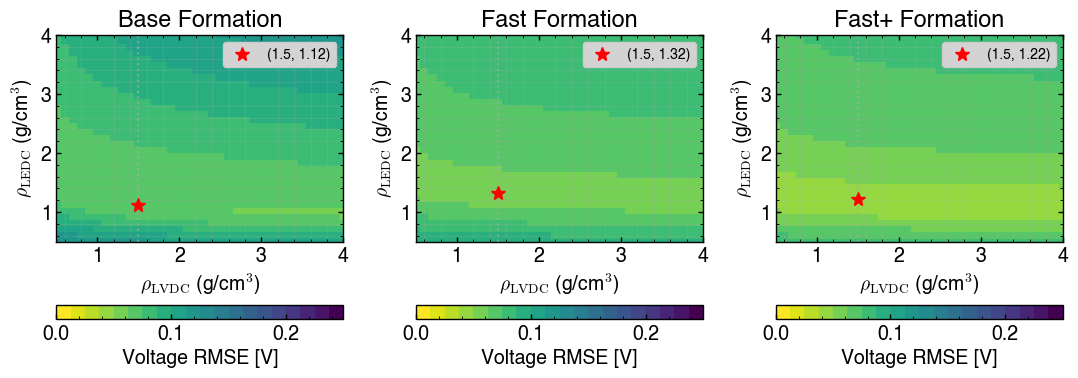

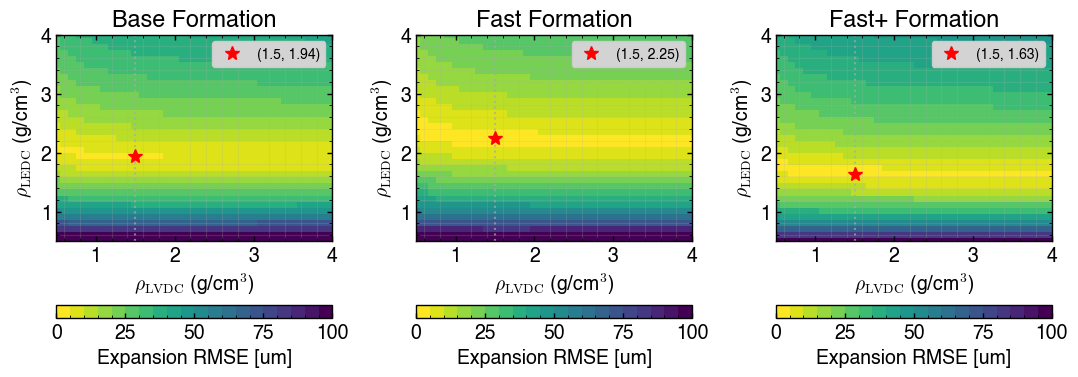

In [4]:
%reload_ext autoreload
%matplotlib inline
# Load the pickled simulation results
with open('notebooks_2026/data/simulation_results_density_sweep_20260426.pkl', 'rb') as f:
    sim_results = pickle.load(f)
rho_ec_vec = np.linspace(0.5, 4.0, 35)
rho_vc_vec = np.linspace(0.5, 4.0, 36)

simutils.plot_heatmaps_rho(rho_ec_vec, rho_vc_vec,
                            sim_results['rmse1_v_mat'], sim_results['rmse2_v_mat'], sim_results['rmse3_v_mat'], 'Voltage RMSE [V]',
                            zmin=0, zmax=0.25, tosave=True, savename='outputs/figures/heatmap_rho_rmse_v.svg', to_annotate=True)
simutils.plot_heatmaps_rho(rho_ec_vec, rho_vc_vec,
                            sim_results['rmse1_e_mat'], sim_results['rmse2_e_mat'], sim_results['rmse3_e_mat'], 'Expansion RMSE [um]',
                            zmin=0, zmax=100, tosave=True, savename='outputs/figures/heatmap_rho_rmse_e.svg', to_annotate=True)

In [5]:
# Pin rho_VC = 1.5 and find the per-protocol argmin in rho_EC at that slice.
# rmse_e is in micrometers (um); rho values in g/cm^3.
rho_vc_fixed = 1.5
j_fixed = int(np.argmin(np.abs(rho_vc_vec - rho_vc_fixed)))
print(f'Pinning rho_VC at {rho_vc_vec[j_fixed]:.3f} g/cm^3 (column index {j_fixed})')
print()

proto_keys = [
    ('Base',  'rmse1_e_mat'),
    ('Fast',  'rmse2_e_mat'),
    ('Fast+', 'rmse3_e_mat'),
]

print(f'{"Protocol":7s}  {"rho_EC":>7s}  {"rho_VC":>7s}  {"rmse_e (um)":>12s}')
print('-' * 42)
for label, key in proto_keys:
    mat = sim_results[key]
    col = mat[:, j_fixed]
    i_min = int(np.nanargmin(col))
    rho_ec_opt = rho_ec_vec[i_min]
    rmse_e_min = float(col[i_min])
    print(f'{label:7s}  {rho_ec_opt:7.3f}  {rho_vc_vec[j_fixed]:7.3f}  {rmse_e_min:12.3f}')

Pinning rho_VC at 1.500 g/cm^3 (column index 10)

Protocol   rho_EC   rho_VC   rmse_e (um)
------------------------------------------
Base       1.941    1.500         4.843
Fast       2.250    1.500         3.630
Fast+      1.632    1.500         3.754
